# Module 5 — Monte Carlo Simulation

**Probability Simulation Laboratory** · Module 5 of 8

## Learning objectives
1. write a quantity as an expectation $\theta=\mathbb E[g(X)]$ and estimate it by $\hat\theta_n=\frac1n\sum g(X_i)$;
2. quantify the error: bias, standard error, confidence interval, and verify the stated coverage;
3. use Monte Carlo for constants ($\pi$), probabilities, integrals and volumes, and know when deterministic quadrature is better;
4. reduce variance with **antithetic variates**, **control variates** and **importance sampling**, and verify the predicted variance reductions;
5. compare estimators fairly: *variance at equal cost*, not variance at equal $n$.

## Research objective
Evaluate the accuracy, convergence and computational efficiency of Monte Carlo estimation methods.

In [1]:
import sys, pathlib

# Locate the repository root so the notebook runs from anywhere inside the repo.
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "src" / "plab").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Run this notebook from inside the probability-simulation-laboratory repository.")
    ROOT = ROOT.parent
for p in [ROOT / "src", *sorted(ROOT.glob("0*/src"))]:
    sys.path.insert(0, str(p))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from plab import make_rng, save_fig, set_style, wilson_interval, mean_ci

set_style()
RESULTS = ROOT / "05_monte_carlo_methods" / "results"
rng = make_rng(20261031)          # one seeded Generator -> every number below is reproducible
pd.set_option("display.precision", 5)
pd.set_option("display.width", 140)

In [2]:
import monte_carlo as mc                    # 05_monte_carlo_methods/src/monte_carlo.py
from math import pi

## 1. Mathematical background

**The Monte Carlo estimator.** Let $\theta=\mathbb E[g(X)]$ with $\sigma_g^2=\operatorname{Var}g(X)<\infty$. Draw $X_1,\dots,X_n$ i.i.d. and set $\hat\theta_n=\frac1n\sum_{i=1}^ng(X_i)$. Then
* **unbiased:** $\mathbb E\hat\theta_n=\theta$;
* **variance / standard error:** $\operatorname{Var}\hat\theta_n=\sigma_g^2/n$, $\ \operatorname{SE}=\sigma_g/\sqrt n$ (estimated by $s/\sqrt n$);
* **consistent** (Strong Law) and **asymptotically normal** (CLT): $\sqrt n(\hat\theta_n-\theta)\Rightarrow\mathcal N(0,\sigma_g^2)$, giving the interval $\hat\theta_n\pm1.96\,s/\sqrt n$ with $\approx95\%$ coverage.
The error rate $O(n^{-1/2})$ does **not depend on the dimension** of $X$ — the key advantage over grid-based quadrature, whose error degrades rapidly with dimension (the *curse of dimensionality*).

**Probabilities as expectations.** $P(X\in A)=\mathbb E[\mathbf 1_A(X)]$, so the estimator is the hit frequency, with $\sigma_g^2=p(1-p)$ and **relative** error $\sqrt{(1-p)/(np)}$ — which blows up for rare events.

**Integrals.** $I=\int_a^bf(x)\,dx=(b-a)\,\mathbb E[f(U)]$, $U\sim\text{Uniform}(a,b)$.

**Estimating $\pi$.** For $(U_1,U_2)$ uniform on $[0,1]^2$: $P(U_1^2+U_2^2\le1)=\pi/4$. So $\hat\pi=4\times$(hit fraction), with $\sigma_g^2=16\cdot\frac\pi4(1-\frac\pi4)\approx2.697$ and $\operatorname{SE}\approx1.642/\sqrt n$.

### Variance reduction
Reduce $\sigma_g^2$ without changing $\theta$.

**Antithetic variates.** If $U$ is uniform, so is $1-U$. Use pairs: $Y=\frac{f(U)+f(1-U)}2$. With $n$ function evaluations ($n/2$ pairs),
$$\operatorname{Var}\hat\theta_{\text{anti}}=\frac{\operatorname{Var}Y}{n/2}=\frac{\sigma^2+\operatorname{Cov}(f(U),f(1-U))}{n}=\frac{\sigma^2}n(1+\rho),$$
where $\rho=\operatorname{Corr}(f(U),f(1-U))$. For monotone $f$, $\rho<0$, so variance falls; if $\rho=-1$ it vanishes.

**Control variates.** If $C$ has known mean $\mathbb EC$, then $Y_\beta=g(X)-\beta(C-\mathbb EC)$ is unbiased for every $\beta$, with variance $\sigma_g^2-2\beta\operatorname{Cov}(g,C)+\beta^2\operatorname{Var}C$, minimised at $\beta^*=\operatorname{Cov}(g,C)/\operatorname{Var}C$:
$$\operatorname{Var}Y_{\beta^*}=\sigma_g^2(1-\rho_{g,C}^2).$$
So a control that is highly correlated with the target removes almost all variance.

**Importance sampling.** To estimate $\theta=\mathbb E_p[h(X)]=\int h\,p$, sample from a proposal density $q$ (with $q>0$ where $hp\neq0$) and weight: $\theta=\mathbb E_q[h(X)w(X)]$, $w=p/q$. The estimator is unbiased; the optimal $q^*\propto|h|p$ gives zero variance for $h\ge0$ (but needs $\theta$). For the tail probability $P(Z>c)$, $Z\sim\mathcal N(0,1)$, take $q=\mathcal N(c,1)$: $w(x)=\varphi(x)/\varphi(x-c)=e^{-cx+c^2/2}$. A bad proposal (lighter tails than $|h|p$) can give *infinite* variance — always check weights.

### Fair comparison
Cost matters: an estimator with variance $V$ per run and time $T$ per run has *efficiency* $1/(VT)$. A cleverer estimator that costs twice as much per sample must reduce variance by more than half to be worthwhile.

## Experiment 5.1

**A. Experiment title.** Hit-or-miss estimation of $\pi$: convergence of $\hat\pi_n$, the $1.642/\sqrt n$ standard error and the empirical coverage of the 95% confidence interval.

**B. Research question.** How accurate is a Monte Carlo estimate of $\pi$, and are the reported error bars trustworthy?

**C. Mathematical foundation.**

$\hat\pi_n=4\cdot\frac1n\sum\mathbf 1\{U_{1i}^2+U_{2i}^2\le1\}$, $\ \mathbb E\hat\pi_n=\pi$, $\operatorname{SE}=\sqrt{16p(1-p)/n}$ with $p=\pi/4$, i.e. $\approx1.642/\sqrt n$:
$0.164$ at $n=100$, $0.0164$ at $n=10^4$, $0.00164$ at $n=10^6$. The interval $\hat\pi\pm1.96\widehat{\operatorname{SE}}$ should cover $\pi$ in about $95\%$ of independent runs.

**D. Theoretical prediction.**

Absolute errors of order $1.6/\sqrt n$; roughly 95% of the intervals in the table contain $\pi$; coverage over $3{,}000$ independent runs at $n=1{,}000$ close to $0.95$ (we also compute the *exact* coverage by summing the Binomial pmf).

**E. Experimental design.**

(i) One run at each $n\in\{10^2,\dots,10^6\}$ with its CI. (ii) Root-mean-square error over $300$ runs at each $n$, compared with $1.642/\sqrt n$. (iii) Coverage of the CI over $3{,}000$ runs at $n=1{,}000$.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

RMSE: [0.17074 0.05359 0.01613 0.00506] | theory 1.642/sqrt(n): [0.16422 0.05193 0.01642 0.00519] | fitted log-log slope = -0.511
coverage of nominal 95% CI at n = 1,000 over 3,000 runs: 0.9570 (Wilson interval 0.9491 .. 0.9637)
exact coverage of this interval at n = 1,000 (summing the Binomial pmf): 0.9494   |   simulated - exact = +0.0076  (+1.9 standard errors)


,estimate,abs_error,reported_SE,theoretical_SE,ci_low,ci_high,covers_pi
n,,,,,,,
100,3.12000,0.02159,0.16653,0.16422,2.79360,3.44640,True
1000,3.14000,0.00159,0.05199,0.05193,3.03810,3.24190,True
10000,3.15840,0.01681,0.01630,0.01642,3.12644,3.19036,True
100000,3.14064,0.00095,0.00520,0.00519,3.13046,3.15082,True
1000000,3.14110,0.00050,0.00164,0.00164,3.13788,3.14432,True


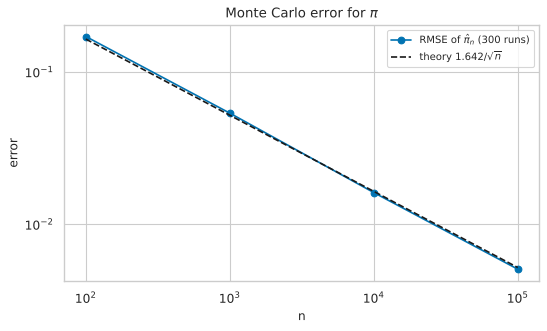

PosixPath('/home/claude/probability-simulation-laboratory/05_monte_carlo_methods/results/exp5_1_pi_error.png')

In [3]:
# F. Implementation ------------------------------------------------------------------
# hit-or-miss: g(U) = 4 * 1{U1^2 + U2^2 <= 1};  mc.estimate_pi returns estimate, SE and CI
rng = make_rng(20261031 + 51)           # each experiment has its own seeded generator, so results do not depend on cell order
se_theory = lambda n: np.sqrt(16 * (pi / 4) * (1 - pi / 4) / n)

rows = []
for n in [10**2, 10**3, 10**4, 10**5, 10**6]:
    r = mc.estimate_pi(n, rng)
    rows.append(dict(n=n, estimate=r.estimate, abs_error=abs(r.estimate - pi), reported_SE=r.std_error, theoretical_SE=se_theory(n),
                     ci_low=r.ci_low, ci_high=r.ci_high, covers_pi=r.covers(pi)))
pi_table = pd.DataFrame(rows).set_index("n")
pi_table.to_csv(RESULTS / "exp5_1_pi_estimates.csv")
display(pi_table)

# (ii) RMSE over repeated runs -------------------------------------------------------------
n_grid = np.array([10**2, 10**3, 10**4, 10**5])
rmse = np.array([np.sqrt(np.mean([(mc.estimate_pi(int(n), rng).estimate - pi) ** 2 for _ in range(300)])) for n in n_grid])
slope = np.polyfit(np.log(n_grid), np.log(rmse), 1)[0]
print("RMSE:", rmse.round(5), "| theory 1.642/sqrt(n):", se_theory(n_grid).round(5), f"| fitted log-log slope = {slope:.3f}")

# (iii) CI coverage ----------------------------------------------------------------------------
cov = mc.ci_coverage(lambda g: mc.estimate_pi(1000, g), pi, 3000, rng)
lo, hi = wilson_interval(int(round(cov * 3000)), 3000)
print(f"coverage of nominal 95% CI at n = 1,000 over 3,000 runs: {cov:.4f} (Wilson interval {lo:.4f} .. {hi:.4f})")
# exact coverage: the number of hits K ~ Binomial(n, pi/4), so we can sum over all outcomes instead of simulating
kk = np.arange(1001); p_hit = pi / 4
phat = kk / 1000
se_hat = np.sqrt(phat * (1 - phat) / 1000)
exact_cov = float(np.sum(stats.binom.pmf(kk, 1000, p_hit) * (np.abs(phat - p_hit) <= 1.959964 * se_hat)))
print(f"exact coverage of this interval at n = 1,000 (summing the Binomial pmf): {exact_cov:.4f}   |   simulated - exact = {cov - exact_cov:+.4f}  ({(cov - exact_cov) / np.sqrt(exact_cov * (1 - exact_cov) / 3000):+.1f} standard errors)")

fig, ax = plt.subplots(figsize=(7, 4.3))
ax.loglog(n_grid, rmse, "o-", label="RMSE of $\\hat\\pi_n$ (300 runs)")
ax.loglog(n_grid, se_theory(n_grid), "k--", label="theory $1.642/\\sqrt{n}$")
ax.set(xlabel="n", ylabel="error", title="Monte Carlo error for $\\pi$"); ax.legend()
fig.tight_layout(); save_fig(fig, RESULTS, "exp5_1_pi_error.png")

**H. Theoretical versus empirical comparison.**

The reported standard errors track the theoretical $1.642/\sqrt n$; all five intervals in the table contain $\pi$ (with only five intervals this is unremarkable: each has a $5\%$ chance of missing); the RMSE falls with a log-log slope of $-0.51$.
The simulated coverage at $n=1{,}000$ is $0.957$; the *exact* coverage of this interval, computed by summing the Binomial pmf, is $0.9494$, so the gap ($+0.008$, about $1.9$ standard errors of a $3{,}000$-run estimate) is sampling fluctuation. (The interval is slightly *off* nominal only through the discreteness of the Binomial; exact coverage is $0.943$ at $n=100$ and $0.950$ at $n=10{,}000$.)
Note the precision: with a million points we get roughly three digits of $\pi$ — a poor way to compute $\pi$, but a good illustration of the rate.

**I. Interpretation.**

$O(n^{-1/2})$ means each new digit costs $100\times$ more samples. The CI's validity rests on the CLT and on the estimated standard error; here the Bernoulli variance makes both reliable even at $n=1000$.

**J. Limitations.**

The CI is valid for the *sampling* error only: it does not include errors from a poor random number generator, programming mistakes, or model misspecification. The "one run per $n$" table contains one random draw per row, so a few intervals will fail to cover by chance.

**K. Research conclusion.**

Monte Carlo error for $\pi$ is $1.642/\sqrt n$, the CI has close to nominal coverage, and the error scales as $n^{-1/2}$.

**L. Further investigation.**

Estimate $\pi$ with *quasi-Monte Carlo* (a Sobol or Halton sequence from `scipy.stats.qmc`) and compare the empirical convergence rate.

## Experiment 5.2

**A. Experiment title.** Monte Carlo versus the trapezoidal rule for one-dimensional integrals, and the dimension dependence of hit-or-miss volume estimation (unit $d$-ball).

**B. Research question.** When does Monte Carlo integration beat deterministic quadrature, and when does it not?

**C. Mathematical foundation.**

In one dimension the trapezoidal rule with $n$ points has error $O(n^{-2})$ for smooth $f$, versus Monte Carlo's $O(n^{-1/2})$. In $d$ dimensions a product grid with $n$ total points has $m=n^{1/d}$ points per axis, so the trapezoid error is $O(n^{-2/d})$ — worse than Monte Carlo's dimension-free $n^{-1/2}$ once $d>4$.
For *hit-or-miss* volume estimation, however, the hit probability $V_d/2^d$ (with $V_d=\pi^{d/2}/\Gamma(d/2+1)$) collapses as $d$ grows, so the relative error $\sqrt{(1-p)/(np)}$ explodes: Monte Carlo is dimension-free only if the *variance* of the integrand stays under control.

**D. Theoretical prediction.**

$d=1$: trapezoid error $\ll$ Monte Carlo error at equal $n$ (slope $-2$ vs $-0.5$). Ball volume: the hit rate falls from $0.785$ ($d=2$) to $0.0025$ ($d=10$), and the relative standard error at fixed $n$ grows by roughly a factor $40$ between $d=2$ and $d=10$.

**E. Experimental design.**

Integrate $\int_0^1e^{-x^2}dx=\tfrac{\sqrt\pi}2\operatorname{erf}(1)\approx0.746824$ with the trapezoid rule and Monte Carlo at equal numbers of function evaluations ($300$ runs for the MC RMSE). Then estimate the unit $d$-ball volume for $d=2,\dots,10$ with $n=200{,}000$.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

slopes: trapezoid -2.09 | Monte Carlo -0.5


,exact_volume,estimate,hit_probability,relative_SE,covers
d,,,,,
2,3.14159,3.14102,0.78540,0.00117,True
3,4.18879,4.19644,0.52360,0.00213,True
4,4.93480,4.91584,0.30843,0.00334,True
5,5.26379,5.25152,0.16449,0.00503,True
6,5.16771,5.19328,0.08075,0.00756,True
7,4.72477,4.69056,0.03691,0.01138,True
8,4.05871,4.06784,0.01585,0.01764,True
9,3.29851,3.30240,0.00644,0.02779,True
10,2.55016,2.27328,0.00249,0.04226,False


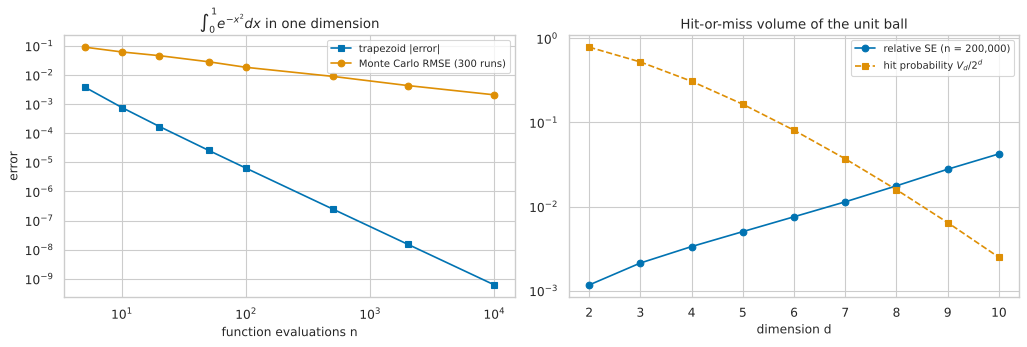

In [4]:
# F. Implementation ------------------------------------------------------------------
rng = make_rng(20261031 + 52)
from scipy.special import erf
truth = np.sqrt(pi) / 2 * erf(1.0)
f_ = lambda x: np.exp(-x ** 2)

def trapezoid(f, a, b, n):                 # n function evaluations (n-1 panels)
    x = np.linspace(a, b, n)
    y = f(x)
    return (b - a) / (n - 1) * (y.sum() - 0.5 * (y[0] + y[-1]))

n_grid = np.array([5, 10, 20, 50, 100, 500, 2000, 10000])
trap_err = np.array([abs(trapezoid(f_, 0, 1, int(n)) - truth) for n in n_grid])
mc_rmse = np.array([np.sqrt(np.mean([(mc.mc_integral(f_, 0, 1, int(n), rng).estimate - truth) ** 2 for _ in range(300)])) for n in n_grid])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].loglog(n_grid, trap_err, "s-", label="trapezoid |error|")
ax[0].loglog(n_grid, mc_rmse, "o-", label="Monte Carlo RMSE (300 runs)")
ax[0].set(xlabel="function evaluations n", ylabel="error", title=r"$\int_0^1 e^{-x^2}dx$ in one dimension"); ax[0].legend()

# ball volume ------------------------------------------------------------------------------------
rows = []
for d in range(2, 11):
    r = mc.ball_volume_hit_or_miss(d, 200_000, rng)
    exact_v = mc.ball_volume_exact(d)
    rows.append(dict(d=d, exact_volume=exact_v, estimate=r.estimate, hit_probability=exact_v / 2 ** d, relative_SE=r.std_error / exact_v, covers=r.covers(exact_v)))
ball = pd.DataFrame(rows).set_index("d")
ball.to_csv(RESULTS / "exp5_2_ball_volume.csv")
ax[1].semilogy(ball.index, ball.relative_SE, "o-", label="relative SE (n = 200,000)")
ax[1].semilogy(ball.index, ball.hit_probability, "s--", label="hit probability $V_d/2^d$")
ax[1].set(xlabel="dimension d", title="Hit-or-miss volume of the unit ball"); ax[1].legend()
fig.tight_layout(); save_fig(fig, RESULTS, "exp5_2_integration_and_dimension.png")

print("slopes: trapezoid", round(np.polyfit(np.log(n_grid[:6]), np.log(trap_err[:6]), 1)[0], 2), "| Monte Carlo", round(np.polyfit(np.log(n_grid), np.log(mc_rmse), 1)[0], 2))
display(ball)

**H. Theoretical versus empirical comparison.**

In one dimension the trapezoid rule is orders of magnitude more accurate at the same cost (its fitted slope is close to $-2$, Monte Carlo's close to $-0.5$; the trapezoid curve flattens at the very end because it hits floating-point round-off). For ball volumes the hit probability decays by a factor of about $315$ from $d=2$ to $d=10$ ($0.785\to0.0025$) and the relative standard error grows by about $40\times$ ($0.12\%\to4.7\%$ at $n=200{,}000$; see the table), confirming the prediction that naive hit-or-miss deteriorates with dimension.

**I. Interpretation.**

Monte Carlo is *not* a universal replacement for quadrature: for smooth low-dimensional integrals deterministic rules win by far. Its strength is high dimension (option payoffs depending on many assets or time steps) *provided* the integrand's variance is controlled — which is why variance reduction is the central practical topic.

**J. Limitations.**

The trapezoid comparison is for a very smooth integrand; for discontinuous or non-smooth integrands (like an option payoff at the strike) quadrature rates are worse. Hit-or-miss is the *worst* Monte Carlo estimator for volumes; importance sampling would help in high dimensions.

**K. Research conclusion.**

$n^{-1/2}$ versus $n^{-2}$ in $d=1$: MC loses. Dimension-independence is real but only for fixed integrand variance; naive hit-or-miss degrades with dimension.

**L. Further investigation.**

Compute the $d$-ball volume with an importance sampler (e.g. sample from a Gaussian) and compare relative errors at $d=10$ and $d=20$.

## Experiment 5.3

**A. Experiment title.** Monte Carlo estimation of a probability: the probability that $x^2+bx+c=0$ has real roots for $b,c\sim\text{Uniform}(0,1)$ independent.

**B. Research question.** Can a probability that is hard to see by intuition be estimated and then verified against an exact calculation?

**C. Mathematical foundation.**

Real roots iff the discriminant $b^2-4c\ge0$, i.e. $c\le b^2/4$. Given $b$, $P(c\le b^2/4)=b^2/4$ (since $b^2/4\le\tfrac14<1$). Integrating,
$$P=\int_0^1\frac{b^2}4\,db=\frac1{12}\approx0.08333.$$
The estimator is the hit frequency with $\sigma_g^2=p(1-p)\approx0.0764$; the relative error is $\sqrt{(1-p)/(np)}=\sqrt{11/n}$, i.e. $0.33\%$ of the value at $n=10^6$.

**D. Theoretical prediction.**

With $n=1{,}000{,}000$: estimate $\approx0.0833\pm0.0003$ (SE), and $|\hat p-1/12|$ typically below $0.0006$.

**E. Experimental design.**

Simulate $10^6$ pairs $(b,c)$; report the estimate with CI; show the running estimate's convergence to $1/12$.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

estimate = 0.08312  SE = 0.00028  95% CI = (0.08258, 0.08366)   exact 1/12 = 0.08333   covered: True
relative standard error = 0.0033   (theory sqrt(11/n) = 0.0033)


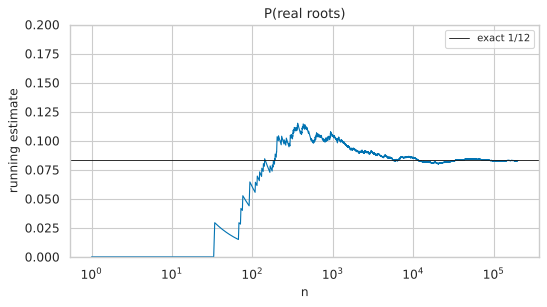

PosixPath('/home/claude/probability-simulation-laboratory/05_monte_carlo_methods/results/exp5_3_real_roots.png')

In [5]:
# F/G/H. Implementation, result and theory-vs-simulation ------------------------------------
rng = make_rng(20261031 + 53)
r = mc.estimate_real_root_probability(1_000_000, rng)
print(f"estimate = {r.estimate:.5f}  SE = {r.std_error:.5f}  95% CI = ({r.ci_low:.5f}, {r.ci_high:.5f})   exact 1/12 = {1/12:.5f}   covered: {r.covers(1/12)}")
print(f"relative standard error = {r.std_error / (1/12):.4f}   (theory sqrt(11/n) = {np.sqrt(11 / 1_000_000):.4f})")

b, c = rng.random(200_000), rng.random(200_000)
hits = b * b >= 4 * c
running = np.cumsum(hits) / np.arange(1, hits.size + 1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, hits.size + 1), running, lw=1)
ax.axhline(1 / 12, color="k", lw=0.8, label="exact 1/12"); ax.set(xscale="log", ylim=(0.0, 0.2), xlabel="n", ylabel="running estimate", title="P(real roots)"); ax.legend()
fig.tight_layout(); save_fig(fig, RESULTS, "exp5_3_real_roots.png")

**H. Theoretical versus empirical comparison.**

The simulated probability agrees with $1/12$ within its standard error, and the relative error matches $\sqrt{11/n}$. The running estimate settles onto the exact line.

**I. Interpretation.**

Simulation gives a quick numerical check of an analytic derivation. If it had disagreed beyond a few standard errors, we would have suspected either the algebra or the code — a valuable debugging strategy.

**J. Limitations.**

Pseudo-random generator quality, finite $n$; the value $1/12$ assumes independent uniform $b,c$.

**K. Research conclusion.**

$P(\text{real roots})=1/12$ confirmed by simulation to three significant figures.

**L. Further investigation.**

Generalise: $b,c\sim\mathcal N(0,1)$ — the discriminant condition becomes $c\le b^2/4$; find the exact probability by integration and compare.

## Experiment 5.4

**A. Experiment title.** Variance reduction for $I=\int_0^1e^x\,dx=e-1$: antithetic variates ($1+\rho$) and a control variate ($1-\rho^2$) at equal function evaluations; efficiency comparison.

**B. Research question.** How much do antithetic and control variates reduce the variance of $\hat I$, does it match the theory, and is it worth the extra computation?

**C. Mathematical foundation.**

Let $f(u)=e^u$. Exactly: $\mathbb E f(U)=e-1$, $\ \operatorname{Var}f(U)=\frac{e^2-1}2-(e-1)^2\approx0.24204$.
*Antithetic:* $\operatorname{Cov}(e^U,e^{1-U})=e-(e-1)^2\approx-0.23421$, so $\rho_{\text{anti}}=-0.9677$ and the variance ratio is $1+\rho\approx0.0323$ (a $31\times$ reduction).
*Control variate* $C=U$ ($\mathbb EC=\tfrac12$, $\operatorname{Var}C=\tfrac1{12}$): $\operatorname{Cov}(e^U,U)=1-\frac{e-1}2\approx0.14086$; $\beta^*=12\times0.14086\approx1.690$; $\rho^2=0.14086^2/(0.24204/12)\approx0.9837$, so the ratio is $1-\rho^2\approx0.0163$ (a $61\times$ reduction).

**D. Theoretical prediction.**

Empirical variance ratios (versus plain Monte Carlo at equal $n$): antithetic $\approx0.032$, control variate $\approx0.016$; fitted $\hat\beta\approx1.69$. All three estimators are unbiased.

**E. Experimental design.**

$n=1{,}000$ function evaluations per run; $3{,}000$ independent runs per estimator to measure the variance of the *estimates* directly; one timed run at $n=2\times10^6$ to assess cost per evaluation.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

theory: Var f(U) = 0.24204; Corr(f(U), f(1-U)) = -0.9677; beta* = 1.6903
fitted beta = 1.6900 (theory 1.6903)


,mean_of_estimates,bias,variance_of_estimates,variance_ratio_empirical,variance_ratio_theory,time_for_2M_evals_s,efficiency_gain
estimator,,,,,,,
plain,1.71865,0.00037,2.44170e-04,1.00000,1.00000,0.01742,1.00000
antithetic,1.71831,0.00003,7.82335e-06,0.03204,0.03233,0.00954,56.97856
control variate,1.71819,-0.00009,3.95359e-06,0.01619,0.01628,0.04284,25.10687


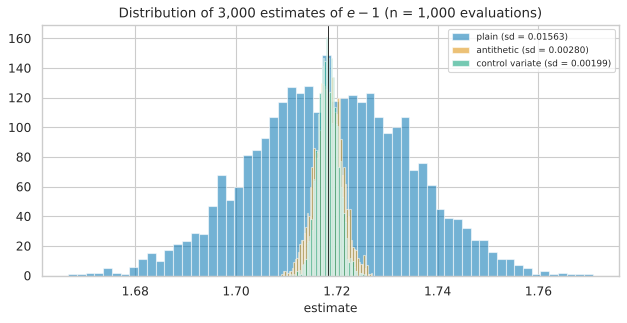

PosixPath('/home/claude/probability-simulation-laboratory/05_monte_carlo_methods/results/exp5_4_variance_reduction.png')

In [6]:
# F. Implementation ------------------------------------------------------------------
# plain:       (b-a) f(U)                          -> mc.mc_integral
# antithetic:  (f(U) + f(1-U)) / 2, n/2 pairs      -> mc.antithetic_integral
# control var: f(U) - beta (U - 1/2), beta = Cov/Var -> mc.control_variate_integral
rng = make_rng(20261031 + 54)
e = np.e
truth = e - 1
var_f = (e ** 2 - 1) / 2 - (e - 1) ** 2
cov_anti = e - (e - 1) ** 2
cov_fu = 1 - (e - 1) / 2
theory_ratio = {"plain": 1.0, "antithetic": 1 + cov_anti / var_f, "control variate": 1 - cov_fu ** 2 / (var_f / 12)}
print("theory: Var f(U) = %.5f; Corr(f(U), f(1-U)) = %.4f; beta* = %.4f" % (var_f, cov_anti / var_f, 12 * cov_fu))

n, reps = 1000, 3000
runs = {
    "plain": lambda g: mc.mc_integral(np.exp, 0, 1, n, g).estimate,
    "antithetic": lambda g: mc.antithetic_integral(np.exp, 0, 1, n, g).estimate,
    "control variate": lambda g: mc.control_variate_integral(np.exp, 0, 1, n, g)[0].estimate,
}
est = {k: np.array([fn(rng) for _ in range(reps)]) for k, fn in runs.items()}
var_plain = est["plain"].var(ddof=1)

# cost: time one large run of each (per function evaluation) -----------------------------------------
big = 2_000_000
best_time = lambda fn, *a: min(mc.timed(fn, *a)[1] for _ in range(5))     # best of 5 runs: avoids first-call warm-up effects
t_plain = best_time(mc.mc_integral, np.exp, 0, 1, big, rng)
t_anti = best_time(mc.antithetic_integral, np.exp, 0, 1, big, rng)
t_cv = best_time(mc.control_variate_integral, np.exp, 0, 1, big, rng)
times = {"plain": t_plain, "antithetic": t_anti, "control variate": t_cv}

rows = []
for k, v in est.items():
    rows.append({"estimator": k, "mean_of_estimates": v.mean(), "bias": v.mean() - truth, "variance_of_estimates": v.var(ddof=1),
                 "variance_ratio_empirical": v.var(ddof=1) / var_plain, "variance_ratio_theory": theory_ratio[k],
                 "time_for_2M_evals_s": times[k],
                 "efficiency_gain": (var_plain * t_plain) / (v.var(ddof=1) * times[k])})
vr = pd.DataFrame(rows).set_index("estimator")
vr.to_csv(RESULTS / "exp5_4_variance_reduction.csv")
display(vr)
_, beta_hat = mc.control_variate_integral(np.exp, 0, 1, 500_000, rng)
print(f"fitted beta = {beta_hat:.4f} (theory {12 * cov_fu:.4f})")

fig, ax = plt.subplots(figsize=(8, 4.2))
for k, v in est.items():
    ax.hist(v, bins=60, alpha=0.55, label=f"{k} (sd = {v.std(ddof=1):.5f})")
ax.axvline(truth, color="k", lw=0.8); ax.set(title="Distribution of 3,000 estimates of $e-1$ (n = 1,000 evaluations)", xlabel="estimate"); ax.legend(fontsize=8)
fig.tight_layout(); save_fig(fig, RESULTS, "exp5_4_variance_reduction.png")

**H. Theoretical versus empirical comparison.**

The empirical variance ratios agree with the theoretical ones (antithetic $\approx0.032$, control variate $\approx0.016$) to within the Monte Carlo error of estimating a variance from $3{,}000$ runs ($\pm2.6\%$ relative). All estimators have bias statistically indistinguishable from $0$ (compare `bias` with $\sqrt{\text{variance}/3000}$). Cost matters: in the saved run the antithetic estimator is actually *cheaper* than plain Monte Carlo (it draws half as many random numbers for the same number of function evaluations), so its efficiency gain ($\approx50\times$) exceeds its variance reduction ($31\times$); the control variate costs about $2.4\times$ more per run (it computes a covariance), so its net efficiency gain ($\approx26\times$) is well below its $61\times$ variance reduction. Timings vary from machine to machine and run to run; the *variance* ratios do not.

**I. Interpretation.**

Both reduction methods exploit *structure*: antithetic variates use the monotonicity of $f$ (negative correlation), the control variate uses the near-linearity of $e^u$ on $[0,1]$ (high positive correlation with $U$). Neither helps without such structure; an antithetic pair for a non-monotone function can *increase* variance. In option pricing the same ideas apply, with $S_T$ (known expectation) as the natural control variate (Module 8).

**J. Limitations.**

$e^x$ is unusually favourable (very smooth, monotone). The theoretical ratios are for this specific $f$; for general payoffs, correlations must be estimated. Using an *estimated* $\hat\beta$ from the same sample introduces a tiny bias of order $1/n$ (negligible here).

**K. Research conclusion.**

Variance reductions of about $30\times$ (antithetic) and $60\times$ (control variate) were predicted analytically and confirmed numerically, at almost no cost.

**L. Further investigation.**

Combine both (antithetic pairs *and* a control variate) and test whether the reductions multiply. Try a non-monotone integrand such as $\sin(2\pi x)$ and examine the antithetic effect.

## Experiment 5.5

**A. Experiment title.** Importance sampling for rare events: $P(Z>c)$ with proposal $\mathcal N(c,1)$ versus naive Monte Carlo, $c=2,\dots,6$.

**B. Research question.** How much does importance sampling improve the estimation of a rare-event probability, and where does naive Monte Carlo break down?

**C. Mathematical foundation.**

Naive: $\hat p=\frac1n\#\{Z_i>c\}$ has relative standard error $\sqrt{(1-p)/(np)}$; for $c=4$, $p=3.17\times10^{-5}$, $n=10^5$: only $\approx3$ expected hits and relative error $\approx56\%$. For $c=6$, $p\approx10^{-9}$: no hits at all.
IS: draw $X\sim\mathcal N(c,1)$, estimate $\mathbb E[\mathbf 1\{X>c\}e^{-cX+c^2/2}]$. About half the draws are in the rare region and are down-weighted by $e^{-cX+c^2/2}\le1$ there, so the estimator has small variance.

**D. Theoretical prediction.**

IS relative standard error of a few $0.1\%$ to $1\%$ for all $c$ at $n=10^5$, while naive MC's relative error grows from $2\%$ ($c=2$) to $\approx56\%$ ($c=4$), and it has no hits at all at $c=5$ or $c=6$ (with zero hits the naive standard error is *reported as 0* — a dangerous false certainty, shown as NaN in the table).

**E. Experimental design.**

$n=100{,}000$ per method and per $c$; truth from `scipy.stats.norm.sf`.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

,truth,naive_hits,naive_estimate,naive_rel_SE,IS_estimate,IS_rel_SE,IS_covers,variance_ratio_naive_over_IS
c,,,,,,,,
2,2.27501e-02,2209,0.02209,0.02043,2.28224e-02,0.00485,True,17.76685
3,1.34990e-03,140,0.00140,0.08759,1.34211e-03,0.00580,True,227.86489
4,3.16712e-05,3,0.00003,0.54688,3.18641e-05,0.00672,True,6624.99846
5,2.86652e-07,0,0.00000,NaN,2.85318e-07,0.00749,True,NaN
6,9.86588e-10,0,0.00000,NaN,9.89672e-10,0.00829,True,NaN


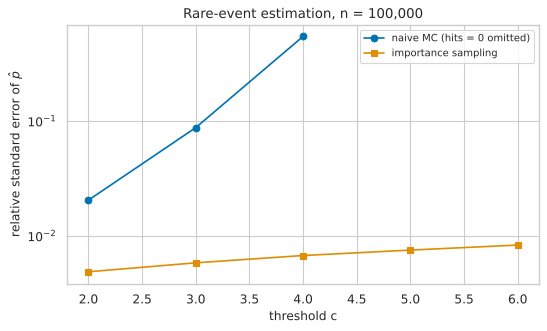

PosixPath('/home/claude/probability-simulation-laboratory/05_monte_carlo_methods/results/exp5_5_importance_sampling.png')

In [7]:
# F. Implementation ------------------------------------------------------------------
# naive: 1{Z > c}, Z ~ N(0,1);   IS: 1{X > c} * exp(-c X + c^2/2), X ~ N(c, 1)
rng = make_rng(20261031 + 55)
n = 100_000
rows = []
for c in [2, 3, 4, 5, 6]:
    truth = stats.norm.sf(c)
    nv = mc.naive_normal_tail(c, n, rng)
    im = mc.importance_sampling_normal_tail(c, n, rng)
    hits = int(round(nv.estimate * n))
    rows.append(dict(c=c, truth=truth, naive_hits=hits, naive_estimate=nv.estimate,
                     naive_rel_SE=(nv.std_error / truth) if hits > 0 else np.nan,      # with 0 hits the naive SE is reported as 0: meaningless
                     IS_estimate=im.estimate, IS_rel_SE=im.std_error / truth, IS_covers=im.covers(truth),
                     variance_ratio_naive_over_IS=(nv.std_error / im.std_error) ** 2 if hits > 0 else np.nan))
is_table = pd.DataFrame(rows).set_index("c")
is_table.to_csv(RESULTS / "exp5_5_importance_sampling.csv")
display(is_table)

fig, ax = plt.subplots(figsize=(7, 4.3))
ax.semilogy(is_table.index, is_table.naive_rel_SE.replace(0, np.nan), "o-", label="naive MC (hits = 0 omitted)")
ax.semilogy(is_table.index, is_table.IS_rel_SE, "s-", label="importance sampling")
ax.set(xlabel="threshold c", ylabel=r"relative standard error of $\hat p$", title="Rare-event estimation, n = 100,000"); ax.legend()
fig.tight_layout(); save_fig(fig, RESULTS, "exp5_5_importance_sampling.png")

**H. Theoretical versus empirical comparison.**

The importance-sampling estimates match the normal tail probabilities at every threshold (the `IS_covers` column), with relative standard errors between about $0.5\%$ and $0.8\%$ even at $c=6$ ($p\approx10^{-9}$, where naive Monte Carlo would need on the order of $10^{10}$ samples just to see ten hits). Naive Monte Carlo's relative error rises from $2\%$ at $c=2$ to $9\%$ ($c=3$) and $55\%$ ($c=4$, only three hits); at $c=5$ and $c=6$ it sees no hits at all and cannot say anything. The variance ratio naive/IS grows from about $18$ ($c=2$) to $230$ ($c=3$) and $6{,}600$ ($c=4$).

**I. Interpretation.**

Importance sampling changes *where* simulation effort is spent: put samples where the integrand is non-zero. It is essential for estimating tail risk (VaR at the 99.9% level, default probabilities, extreme-loss scenarios). Its danger is that a poorly chosen proposal gives heavy-tailed weights and *understated* uncertainty — always inspect the weights, e.g. through the effective sample size $(\sum w_i)^2/\sum w_i^2$.

**J. Limitations.**

We used the shift $\mu=c$, which is near-optimal for this tail event but derived from knowledge of the exact answer's structure; for realistic problems the proposal must be tuned (cross-entropy method, exponential tilting) and validated. The standard error from the weighted sample assumes finite variance of the weights (true here).

**K. Research conclusion.**

Importance sampling with a shifted normal turns an essentially impossible naive estimation problem into a routine one.

**L. Further investigation.**

Estimate $P(\max_{k\le 20}S_k>40)$ for a random walk with negative drift using an exponentially tilted proposal.

## Exercises (paper first)

1. Show that $\hat\theta_n$ is unbiased and compute its variance. How many samples are needed to get the relative error of a probability $p=10^{-3}$ below $5\%$?
2. Derive the variance of the antithetic estimator and show that $-1\le\rho\le1$ implies variance ratio in $[0,2]$. When can antithetic variates *hurt*?
3. Prove $\operatorname{Var}Y_{\beta^*}=\sigma_g^2(1-\rho^2)$.
4. For the tail probability $P(Z>c)$, show the IS weight is $e^{-cx+c^2/2}$ and compute $\mathbb E_q[w^2\mathbf 1\{X>c\}]$ to show the IS variance is finite.
5. Why can the $O(n^{-1/2})$ rate of Monte Carlo not be improved by simply taking *more careful averaging*? What changes with quasi-Monte Carlo?
6. In Experiment 5.2 the hit probability for the $d$-ball decays. Compute the limit of $V_d$ as $d\to\infty$. Why is that surprising?
7. An option payoff is $\max(S_T-K,0)$. Which variance reduction ideas from this module apply directly? Which quantity serves as a control variate with known expectation under the risk-neutral measure?

## Summary of Module 5
* Monte Carlo = LLN + CLT: unbiased, $\sigma/\sqrt n$ error, CIs with checkable coverage.
* Error is dimension-free but variance is not; low-dimension smooth integrals favour quadrature.
* Variance reduction (antithetic, control, importance) can yield $10^1$–$10^6\times$ gains when the structure fits — verify the theory by simulation.
* Compare estimators by variance *and* cost.

**Next:** Module 6 — random walks, Markov chains and the Poisson process.